# Projeto Final - Programação para Ciência de Dados

## Predição de alta aprovação em jogos da Steam

**Alunos:** Lucas Gabriel Hotto, Marcelo Lutz Brum e Vinícius Strzelecki  
**Disciplina:** Programação para Ciência de Dados - 2026.1  
**Entrega:** relatório final (Etapas 1 e 2)  
**Data de acesso à base:** 17/09/2026

Este notebook é a evidência reproduzível do relatório final. Ele carrega e prepara os dados, resume a exploração e executa toda a modelagem, avaliação e visualização com sementes fixas.


## 1. Introdução

A Steam reúne jogos com preços, gêneros, recursos técnicos e níveis muito diferentes de visibilidade. Para um estúdio ou equipe de produto, entender quais características aparecem associadas ao alcance e à aprovação ajuda a selecionar referências de mercado e formular hipóteses para novos projetos. ARC Raiders motivou a escolha do domínio e será apresentado como estudo de caso, enquanto as conclusões gerais usarão o catálogo amplo da Steam.

### Perguntas de negócio

1. Quais gêneros, preços e características estão associados a maior alcance de público entre os jogos lançados no período analisado?
2. Como o preço se relaciona com a aprovação dos jogadores, considerando gênero e ano de lançamento?
3. É possível prever se um jogo terá alta aprovação usando características disponíveis na base?

A terceira pergunta será respondida na Etapa 2. A variável-alvo será definida a partir da taxa de avaliações positivas, usando um número mínimo de avaliações para reduzir a instabilidade de jogos quase sem avaliações. Os campos `Positive` e `Negative`, usados no cálculo do alvo, não poderão entrar como preditores do modelo.

## 2. Os dados

**Fonte:** Steam Games Dataset, publicado por FronkonGames no Kaggle.  
**Link:** https://www.kaggle.com/datasets/fronkongames/steam-games-dataset  
**Licença declarada na página da base:** MIT.  
**Unidade de observação:** um aplicativo/jogo cadastrado na Steam por linha.  
**Arquivo usado:** `games.csv`.

O arquivo original apresenta um defeito no cabeçalho: os nomes `Discount` e `DLC count` aparecem unidos como `DiscountDLC count`, embora cada linha contenha dois valores separados. Por isso, a leitura comum desloca as colunas. A lista corrigida de 40 nomes é fornecida explicitamente na importação.

In [1]:
from pathlib import Path
import os
import ast
import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

DATA_ACESSO = pd.Timestamp("2026-09-17")

candidatos = [
    Path(r"C:/Users/lucas/Downloads/archive/games.csv"),
    Path("data/games.csv"),
    Path("games.csv"),
]

CAMINHO = next((p for p in candidatos if p.exists()), None)
if CAMINHO is None:
    raise FileNotFoundError(
        "games.csv não encontrado. Coloque-o em data/games.csv ou atualize a lista 'candidatos'."
    )

print(f"Arquivo utilizado: {CAMINHO.resolve()}")

Arquivo utilizado: C:\Users\lucas\Downloads\archive\games.csv


In [2]:
COLUNAS_ORIGINAIS = [
    "AppID", "Name", "Release date", "Estimated owners", "Peak CCU",
    "Required age", "Price", "Discount", "DLC count", "About the game",
    "Supported languages", "Full audio languages", "Reviews", "Header image",
    "Website", "Support url", "Support email", "Windows", "Mac", "Linux",
    "Metacritic score", "Metacritic url", "User score", "Positive", "Negative",
    "Score rank", "Achievements", "Recommendations", "Notes",
    "Average playtime forever", "Average playtime two weeks",
    "Median playtime forever", "Median playtime two weeks", "Developers",
    "Publishers", "Categories", "Genres", "Tags", "Screenshots", "Movies"
]

COLUNAS_USADAS = [
    "AppID", "Name", "Release date", "Estimated owners", "Peak CCU",
    "Required age", "Price", "Discount", "DLC count", "Windows", "Mac",
    "Linux", "Metacritic score", "User score", "Positive", "Negative",
    "Achievements", "Recommendations", "Average playtime forever",
    "Median playtime forever", "Developers", "Publishers", "Categories",
    "Genres", "Tags"
]

df = pd.read_csv(
    CAMINHO,
    header=None,
    skiprows=1,
    names=COLUNAS_ORIGINAIS,
    usecols=COLUNAS_USADAS,
    low_memory=False,
)

print(f"Dimensão carregada: {df.shape[0]:,} linhas × {df.shape[1]} colunas selecionadas")
df.head(3)

Dimensão carregada: 125,855 linhas × 25 colunas selecionadas


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,Windows,Mac,Linux,Metacritic score,User score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Developers,Publishers,Categories,Genres,Tags
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,True,False,False,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,True,False,False,0,0,252,3,0,231,8,8,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute"
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,True,True,False,0,0,21,3,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec..."


### Dicionário das colunas utilizadas

O trabalho seleciona 25 das 40 colunas originais. URLs, imagens, e-mails e textos técnicos que não contribuem para as perguntas foram deixados fora da tabela analítica para reduzir memória e ruído.

In [3]:
dicionario = pd.DataFrame([
    ("AppID", "Identificador único do aplicativo na Steam", "identificador"),
    ("Name", "Nome do jogo/aplicativo", "texto"),
    ("Release date", "Data de lançamento informada", "temporal"),
    ("Estimated owners", "Faixa estimada de proprietários", "categórica ordinal"),
    ("Peak CCU", "Pico de jogadores simultâneos", "numérica"),
    ("Required age", "Idade mínima exigida", "numérica/categórica"),
    ("Price", "Preço em dólares", "numérica contínua"),
    ("Discount", "Desconto registrado", "numérica"),
    ("DLC count", "Quantidade de DLCs", "numérica"),
    ("Windows / Mac / Linux", "Compatibilidade por sistema operacional", "categórica binária"),
    ("Metacritic score", "Nota agregada no Metacritic", "numérica"),
    ("User score", "Nota de usuário disponibilizada na fonte", "numérica"),
    ("Positive / Negative", "Contagens de avaliações positivas e negativas", "numérica"),
    ("Achievements", "Quantidade de conquistas", "numérica"),
    ("Recommendations", "Quantidade de recomendações", "numérica"),
    ("Average playtime forever", "Tempo médio total de jogo, em minutos", "numérica"),
    ("Median playtime forever", "Mediana do tempo total de jogo, em minutos", "numérica"),
    ("Developers", "Desenvolvedora(s)", "categórica"),
    ("Publishers", "Publicadora(s)", "categórica"),
    ("Categories", "Recursos/categorias da página Steam", "categórica multivalorada"),
    ("Genres", "Gêneros informados", "categórica multivalorada"),
    ("Tags", "Marcadores atribuídos ao jogo", "categórica multivalorada"),
], columns=["Coluna", "Significado", "Papel inicial"])
dicionario

,Coluna,Significado,Papel inicial
0,AppID,Identificador único do aplicativo na Steam,identificador
1,Name,Nome do jogo/aplicativo,texto
2,Release date,Data de lançamento informada,temporal
3,Estimated owners,Faixa estimada de proprietários,categórica ordinal
4,Peak CCU,Pico de jogadores simultâneos,numérica
5,Required age,Idade mínima exigida,numérica/categórica
6,Price,Preço em dólares,numérica contínua
7,Discount,Desconto registrado,numérica
8,DLC count,Quantidade de DLCs,numérica
9,Windows / Mac / Linux,Compatibilidade por sistema operacional,categórica binária


## 3. Entendimento dos dados

In [4]:
resumo_estrutura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "não_nulos": df.notna().sum(),
    "ausentes": df.isna().sum(),
    "ausentes_%": df.isna().mean().mul(100).round(2),
    "distintos": df.nunique(dropna=True),
}).sort_values("ausentes_%", ascending=False)
resumo_estrutura

,tipo,não_nulos,ausentes,ausentes_%,distintos
Tags,str,83353,42502,33.77,77184
Categories,str,116889,8966,7.12,14058
Publishers,str,116933,8922,7.09,64607
Developers,str,117406,8449,6.71,72859
Genres,str,117432,8423,6.69,2922
Name,str,125854,1,0.00,124644
Release date,str,125855,0,0.00,5141
Estimated owners,str,125855,0,0.00,14
AppID,int64,125855,0,0.00,125855
DLC count,int64,125855,0,0.00,117


In [5]:
ausentes_relevantes = resumo_estrutura.query("5 <= `ausentes_%` <= 50")[["ausentes", "ausentes_%", "distintos"]]
ausentes_relevantes

,ausentes,ausentes_%,distintos
Tags,42502,33.77,77184
Categories,8966,7.12,14058
Publishers,8922,7.09,64607
Developers,8449,6.71,72859
Genres,8423,6.69,2922


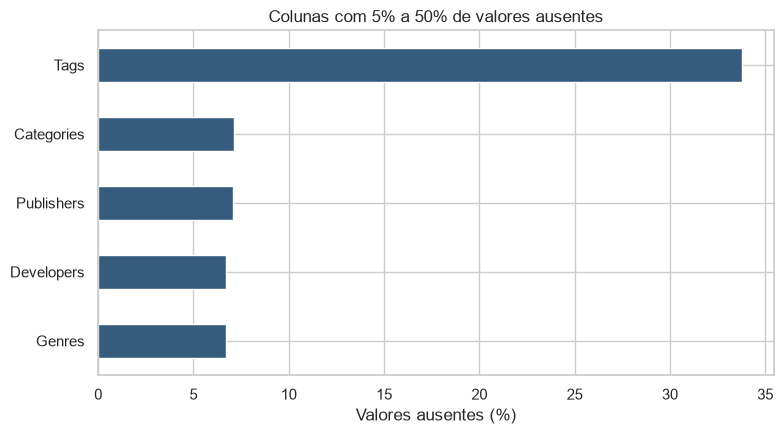

In [6]:
ax = ausentes_relevantes.sort_values("ausentes_%")["ausentes_%"].plot(
    kind="barh", figsize=(8, 4.5), color="#355C7D"
)
ax.set_title("Colunas com 5% a 50% de valores ausentes")
ax.set_xlabel("Valores ausentes (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [7]:
df["Release date parsed"] = pd.to_datetime(df["Release date"], errors="coerce")

diagnostico = pd.Series({
    "linhas": len(df),
    "colunas selecionadas": df.shape[1] - 1,
    "AppID duplicado": int(df["AppID"].duplicated().sum()),
    "nome ausente": int(df["Name"].isna().sum()),
    "data inválida ou ausente": int(df["Release date parsed"].isna().sum()),
    "preço negativo": int((df["Price"] < 0).sum()),
    "lançamento posterior ao acesso": int((df["Release date parsed"] > DATA_ACESSO).sum()),
})
diagnostico

linhas                            125855
colunas selecionadas                  25
AppID duplicado                        0
nome ausente                           1
data inválida ou ausente               0
preço negativo                         0
lançamento posterior ao acesso         1
dtype: int64

In [8]:
print("Data mínima:", df["Release date parsed"].min().date())
print("Data máxima:", df["Release date parsed"].max().date())
print("Amplitude aproximada em anos:", round((df["Release date parsed"].max() - df["Release date parsed"].min()).days / 365.25, 1))

Data mínima: 1997-06-30
Data máxima: 2026-12-01
Amplitude aproximada em anos: 29.4


In [9]:
numericas_chave = [
    "Peak CCU", "Required age", "Price", "Discount", "DLC count",
    "Metacritic score", "User score", "Positive", "Negative",
    "Achievements", "Recommendations", "Average playtime forever",
    "Median playtime forever"
]
df[numericas_chave].describe(percentiles=[.25, .5, .75, .9, .95, .99]).T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Peak CCU,"125,855.00",53.19,"3,681.08",0.00,0.00,0.00,0.00,2.00,8.00,215.46,"1,013,936.00"
Required age,"125,855.00",0.17,1.64,0.00,0.00,0.00,0.00,0.00,0.00,10.00,21.00
Price,"125,855.00",4.81,12.49,0.00,0.59,2.39,5.54,9.99,14.99,29.99,999.98
Discount,"125,855.00",17.90,28.63,0.00,0.00,0.00,37.00,70.00,80.00,90.00,100.00
DLC count,"125,855.00",0.54,14.33,0.00,0.00,0.00,0.00,1.00,2.00,7.00,"3,703.00"
Metacritic score,"125,855.00",2.50,13.49,0.00,0.00,0.00,0.00,0.00,0.00,80.00,97.00
User score,"125,855.00",0.02,1.38,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00
Positive,"125,855.00","1,018.18","27,727.82",0.00,0.00,4.00,35.00,276.00,"1,031.30","12,869.52","7,642,084.00"
Negative,"125,855.00",164.88,"5,305.00",0.00,0.00,1.00,10.00,68.00,215.00,"2,068.00","1,173,003.00"
Achievements,"125,855.00",17.92,139.70,0.00,0.00,2.00,19.00,38.00,55.00,100.00,"9,821.00"


### Verificação dos requisitos da disciplina

As categorias multivaloradas são mantidas como texto no arquivo, mas representam atributos categóricos. `Price` é contínua, enquanto contagens como avaliações e tempo de jogo oferecem outras variáveis numéricas. A coluna temporal cobre muito mais de 12 meses. A ausência entre 5% e 50% aparece em campos como `Genres`, `Developers`, `Publishers`, `Categories` e `Tags`.

In [10]:
validacao = pd.DataFrame([
    ("Pelo menos 2.000 linhas", len(df), len(df) >= 2000),
    ("Pelo menos 10 colunas de conteúdo", df.shape[1] - 2, df.shape[1] - 2 >= 10),
    ("Pelo menos 3 numéricas", len(numericas_chave), len(numericas_chave) >= 3),
    ("Ao menos 1 numérica contínua", df["Price"].nunique(), df["Price"].nunique() > 20),
    ("Pelo menos 3 categóricas", 8, True),
    ("Uma categórica com mais de 5 valores", df["Genres"].nunique(), df["Genres"].nunique() > 5),
    ("Data cobrindo pelo menos 12 meses", round((df["Release date parsed"].max() - df["Release date parsed"].min()).days / 30.44), True),
    ("Pelo menos 1 coluna textual", df["Name"].nunique(), True),
    ("Alguma coluna entre 5% e 50% ausente", len(ausentes_relevantes), len(ausentes_relevantes) >= 1),
    ("Alvo possível para a Etapa 2", "alta_aprovacao", True),
], columns=["Requisito", "Evidência", "Atende"])
validacao

,Requisito,Evidência,Atende
0,Pelo menos 2.000 linhas,125855,True
1,Pelo menos 10 colunas de conteúdo,24,True
2,Pelo menos 3 numéricas,13,True
3,Ao menos 1 numérica contínua,953,True
4,Pelo menos 3 categóricas,8,True
5,Uma categórica com mais de 5 valores,2922,True
6,Data cobrindo pelo menos 12 meses,353,True
7,Pelo menos 1 coluna textual,124644,True
8,Alguma coluna entre 5% e 50% ausente,5,True
9,Alvo possível para a Etapa 2,alta_aprovacao,True


## 4. Preparação dos dados

Decisões adotadas:

- Manter apenas lançamentos ocorridos até a data de acesso. A base contém títulos anunciados para o futuro, que ainda não tiveram a mesma oportunidade de acumular público e avaliações.
- Remover somente duplicatas exatas de `AppID`, caso existam. O identificador representa a unidade de observação.
- Não substituir ausências em gênero, desenvolvedora ou tags durante esta etapa. A ausência é informação sobre a cobertura da fonte e o preenchimento artificial criaria categorias sem evidência.
- Preservar preço zero, pois ele pode indicar um jogo gratuito.
- Tratar notas iguais a zero com cautela. Em vários campos, zero pode indicar que a nota não está disponível, e não uma avaliação real de zero.
- Criar variáveis derivadas apenas quando ligadas às perguntas: ano de lançamento, total de avaliações, taxa de aprovação, indicador de jogo gratuito, gênero principal e ponto médio da faixa estimada de proprietários.

In [11]:
df_prep = df.copy()
df_prep["Release date"] = df_prep.pop("Release date parsed")

# Mantém jogos lançados até a data em que a base foi obtida.
df_prep = df_prep.loc[df_prep["Release date"].notna() & (df_prep["Release date"] <= DATA_ACESSO)].copy()

# A unidade de observação é AppID.
df_prep = df_prep.drop_duplicates(subset="AppID", keep="first")

df_prep["Release year"] = df_prep["Release date"].dt.year
df_prep["Total reviews"] = df_prep["Positive"] + df_prep["Negative"]
df_prep["Approval rate"] = np.where(
    df_prep["Total reviews"] > 0,
    df_prep["Positive"] / df_prep["Total reviews"],
    np.nan,
)
df_prep["Free to play"] = df_prep["Price"].eq(0)
df_prep["Primary genre"] = df_prep["Genres"].str.split(",").str[0].str.strip()

owners_parts = df_prep["Estimated owners"].str.extract(r"^\s*([\d,]+)\s*-\s*([\d,]+)\s*$")
df_prep["Owners lower"] = pd.to_numeric(owners_parts[0].str.replace(",", "", regex=False), errors="coerce")
df_prep["Owners upper"] = pd.to_numeric(owners_parts[1].str.replace(",", "", regex=False), errors="coerce")
df_prep["Owners midpoint"] = (df_prep["Owners lower"] + df_prep["Owners upper"]) / 2

print(f"Linhas antes da preparação: {len(df):,}")
print(f"Linhas depois da preparação: {len(df_prep):,}")
df_prep[["Name", "Release date", "Price", "Total reviews", "Approval rate", "Primary genre", "Owners midpoint"]].head()

Linhas antes da preparação: 125,855
Linhas depois da preparação: 125,854


,Name,Release date,Price,Total reviews,Approval rate,Primary genre,Owners midpoint
0,Black Dragon Mage Playtest,2023-08-01,0.00,0,NaN,NaN,0.00
1,Supipara - Chapter 1 Spring Has Come!,2016-07-29,5.24,255,0.99,Adventure,"10,000.00"
2,Mystery Solitaire The Black Raven,2019-05-06,4.99,24,0.88,Casual,"10,000.00"
3,버튜버 파라노이아 - Vtuber Paranoia,2024-10-31,8.99,0,NaN,Casual,"10,000.00"
4,Maze Quest VR,2025-04-24,4.99,0,NaN,Action,"10,000.00"


In [12]:
# Candidatos para a variável-alvo da Etapa 2.
# O limite de 50 avaliações evita definir sucesso a partir de pouquíssimas opiniões.
amostra_modelo = df_prep.loc[df_prep["Total reviews"] >= 50].copy()
limiar_aprovacao = amostra_modelo["Approval rate"].median()
amostra_modelo["High approval"] = (amostra_modelo["Approval rate"] >= limiar_aprovacao).astype(int)

print(f"Jogos com pelo menos 50 avaliações: {len(amostra_modelo):,}")
print(f"Mediana da aprovação nesse grupo: {limiar_aprovacao:.2%}")
print("Distribuição do alvo:")
print(amostra_modelo["High approval"].value_counts().rename(index={0: "não", 1: "sim"}))

Jogos com pelo menos 50 avaliações: 30,624
Mediana da aprovação nesse grupo: 82.04%
Distribuição do alvo:
High approval
sim    15312
não    15312
Name: count, dtype: int64


### ARC Raiders como estudo de caso

O jogo é localizado pelo nome exato. Os números abaixo descrevem apenas o que estava presente no arquivo em 17/09/2026. Ausência ou zero não devem ser interpretados automaticamente como desempenho real sem conferir o processo de coleta da fonte.

In [13]:
arc = df_prep.loc[
    df_prep["Name"].str.fullmatch("ARC Raiders", case=False, na=False),
    ["AppID", "Name", "Release date", "Price", "Estimated owners", "Peak CCU",
     "Positive", "Negative", "Approval rate", "Genres", "Developers", "Publishers"]
]
arc

,AppID,Name,Release date,Price,Estimated owners,Peak CCU,Positive,Negative,Approval rate,Genres,Developers,Publishers
65261,1808500,ARC Raiders,2025-10-30,31.99,0 - 20000,0,0,0,NaN,Action,Embark Studios,Embark Studios


## Síntese da Etapa 1

A base atende aos requisitos estruturais e oferece variáveis adequadas para modelagem. Os principais cuidados foram o cabeçalho defeituoso, um lançamento futuro, campos categóricos ausentes e zeros que podem representar indisponibilidade. A preparação manteve 125.854 jogos. Para reduzir a instabilidade da taxa de aprovação, a Etapa 2 usa apenas os 30.624 jogos com pelo menos 50 avaliações.


## 5. Etapa 2 - pergunta e objetivo preditivo

**Pergunta escolhida:** é possível prever se um jogo terá alta aprovação usando apenas características cadastrais do jogo?

O problema foi formulado como **classificação binária**. O alvo `High approval` vale 1 quando a taxa de avaliações positivas é igual ou superior à mediana da amostra elegível (82,04%) e 0 nos demais casos. O mínimo de 50 avaliações reduz decisões baseadas em poucos votos.

As features são preço, idade mínima, número de DLCs, conquistas, compatibilidade com Windows/Mac/Linux, ano de lançamento e gênero principal. Avaliações positivas e negativas, total de avaliações e taxa de aprovação são excluídos por construírem o alvo. Pico de jogadores, proprietários, recomendações, tempo de jogo e notas agregadas também são excluídos porque refletem desempenho posterior ao lançamento e tornariam a pergunta menos útil para avaliar um jogo antes de observar sua recepção.


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import clone

SEED = 42
NUM_FEATURES = ["Price", "Required age", "DLC count", "Achievements", "Release year"]
CAT_FEATURES = ["Windows", "Mac", "Linux", "Primary genre"]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "High approval"

model_df = amostra_modelo[FEATURES + [TARGET]].copy()
X = model_df[FEATURES]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

print(f"Treino: {len(X_train):,} jogos | Teste: {len(X_test):,} jogos")
print("Proporção positiva - treino: {:.2%} | teste: {:.2%}".format(y_train.mean(), y_test.mean()))


Treino: 22,968 jogos | Teste: 7,656 jogos
Proporção positiva - treino: 50.00% | teste: 50.00%


## 6. Metodologia e modelos

A divisão estratificada reserva 25% dos jogos para teste e mantém o equilíbrio do alvo. O conjunto de teste não participa do ajuste. Valores numéricos ausentes são substituídos pela mediana do treino; categóricos, pela categoria mais frequente. O gênero é codificado por one-hot encoding. A regressão logística recebe padronização numérica.

Foram comparados três algoritmos vistos em aula:

- **Regressão Logística:** estima a probabilidade da classe positiva por uma função logística. Usa regularização L2 padrão, `C=1` e até 2.000 iterações.
- **Árvore de Decisão:** cria divisões sucessivas nas features. Para controlar overfitting, usa profundidade máxima 8 e ao menos 30 exemplos por folha.
- **Random Forest:** combina 250 árvores treinadas com amostras e subconjuntos de features. Usa profundidade máxima 14 e ao menos 10 exemplos por folha.

A métrica principal é **acurácia**, percentual total de classificações corretas. Ela é adequada porque as classes foram construídas com tamanhos iguais. A acurácia de treino e teste permite avaliar generalização; a matriz de confusão é usada apenas para localizar os dois tipos de erro.


In [15]:
numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
numeric_plain = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])
categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
])

preprocess_scaled = ColumnTransformer([
    ("num", numeric_scaled, NUM_FEATURES),
    ("cat", categorical, CAT_FEATURES),
])
preprocess_plain = ColumnTransformer([
    ("num", numeric_plain, NUM_FEATURES),
    ("cat", categorical, CAT_FEATURES),
])

models = {
    "Regressão Logística": Pipeline([
        ("prep", clone(preprocess_scaled)),
        ("model", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED)),
    ]),
    "Árvore de Decisão": Pipeline([
        ("prep", clone(preprocess_plain)),
        ("model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("prep", clone(preprocess_plain)),
        ("model", RandomForestClassifier(
            n_estimators=250, max_depth=14, min_samples_leaf=10,
            max_features="sqrt", n_jobs=-1, random_state=SEED
        )),
    ]),
}


In [16]:
results = []
predictions = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    pred_train = pipeline.predict(X_train)
    pred_test = pipeline.predict(X_test)
    predictions[name] = pred_test
    results.append({
        "Modelo": name,
        "Acurácia treino": accuracy_score(y_train, pred_train),
        "Acurácia teste": accuracy_score(y_test, pred_test),
    })

results_df = pd.DataFrame(results)
results_df["Diferença treino-teste"] = results_df["Acurácia treino"] - results_df["Acurácia teste"]
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Baseline da classe majoritária: {baseline:.2%}")
display(results_df.assign(**{
    "Acurácia treino": results_df["Acurácia treino"].map(lambda v: f"{v:.2%}"),
    "Acurácia teste": results_df["Acurácia teste"].map(lambda v: f"{v:.2%}"),
    "Diferença treino-teste": results_df["Diferença treino-teste"].map(lambda v: f"{v:.2%}"),
}))


Baseline da classe majoritária: 50.00%


,Modelo,Acurácia treino,Acurácia teste,Diferença treino-teste
0,Regressão Logística,60.01%,60.01%,0.00%
1,Árvore de Decisão,62.90%,60.76%,2.13%
2,Random Forest,66.82%,62.96%,3.86%


## 7. Resultados e validação

O baseline é 50%, pois o alvo é balanceado. O gráfico seguinte compara treino e teste. Uma diferença pequena indica boa generalização; uma diferença grande sugere overfitting. A regularização e os limites de profundidade foram definidos antes da avaliação final para reduzir esse risco.


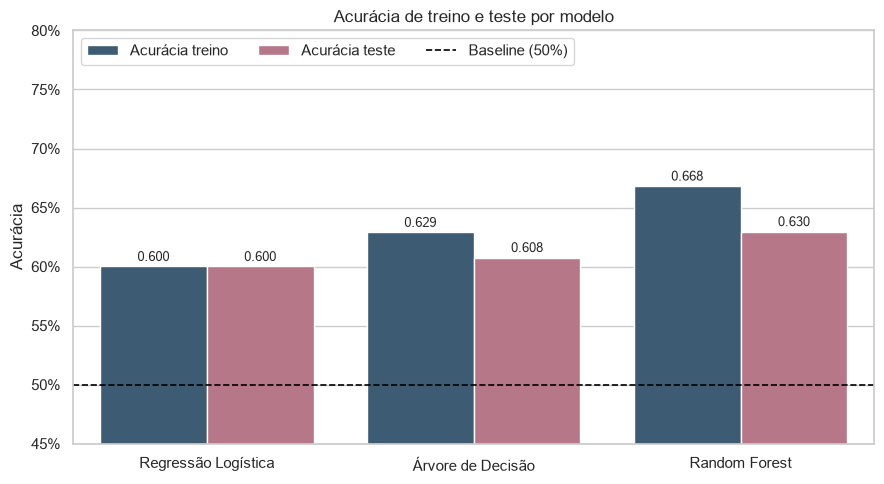

In [17]:
fig_dir = Path("figures_final")
fig_dir.mkdir(exist_ok=True)

plot_df = results_df.melt(
    id_vars="Modelo", value_vars=["Acurácia treino", "Acurácia teste"],
    var_name="Conjunto", value_name="Acurácia"
)
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="Modelo", y="Acurácia", hue="Conjunto", palette=["#355C7D", "#C06C84"])
ax.axhline(baseline, color="black", linestyle="--", linewidth=1.2, label="Baseline (50%)")
ax.set_ylim(0.45, 0.80)
ax.set_title("Acurácia de treino e teste por modelo")
ax.set_xlabel("")
ax.set_ylabel("Acurácia")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=9)
plt.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.savefig(fig_dir / "acuracia_modelos.png", dpi=180, bbox_inches="tight")
plt.show()


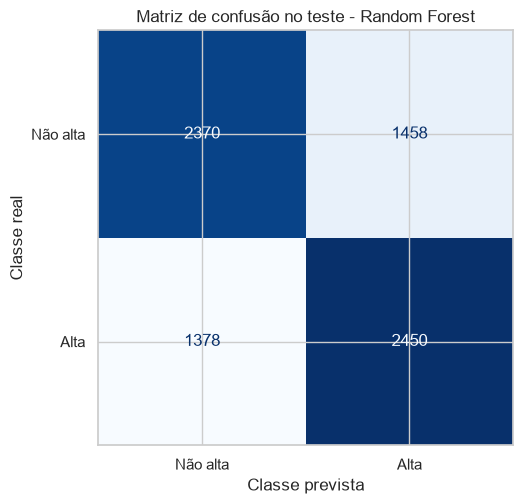

Melhor modelo: Random Forest
Verdadeiros negativos: 2370 | Falsos positivos: 1458
Falsos negativos: 1378 | Verdadeiros positivos: 2450


In [18]:
best_name = results_df.sort_values("Acurácia teste", ascending=False).iloc[0]["Modelo"]
best_pred = predictions[best_name]
cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(figsize=(6.3, 5.2))
ConfusionMatrixDisplay(cm, display_labels=["Não alta", "Alta"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title(f"Matriz de confusão no teste - {best_name}")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.savefig(fig_dir / "matriz_confusao.png", dpi=180, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Melhor modelo: {best_name}")
print(f"Verdadeiros negativos: {tn} | Falsos positivos: {fp}")
print(f"Falsos negativos: {fn} | Verdadeiros positivos: {tp}")


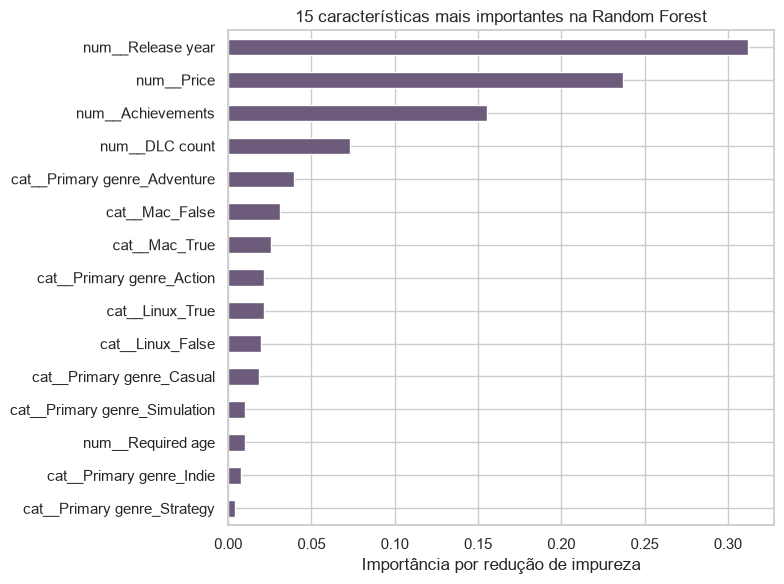

,Importância
num__Release year,0.31
num__Price,0.24
num__Achievements,0.16
num__DLC count,0.07
cat__Primary genre_Adventure,0.04
cat__Mac_False,0.03
cat__Mac_True,0.03
cat__Primary genre_Action,0.02
cat__Linux_True,0.02
cat__Linux_False,0.02


In [19]:
rf = models["Random Forest"]
feature_names = rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names)
top_importances = importances.nlargest(15).sort_values()

plt.figure(figsize=(8, 6))
ax = top_importances.plot(kind="barh", color="#6C5B7B")
ax.set_title("15 características mais importantes na Random Forest")
ax.set_xlabel("Importância por redução de impureza")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(fig_dir / "importancia_features.png", dpi=180, bbox_inches="tight")
plt.show()

top_importances.sort_values(ascending=False).to_frame("Importância").head(10)


## 8. Discussão, limitações e conclusão

O melhor modelo deve ser interpretado pelo desempenho no teste e pela diferença em relação ao treino. A matriz de confusão mostra se o modelo tende mais a classificar jogos comuns como altamente aprovados ou a deixar de reconhecer jogos realmente bem avaliados. A importância da Random Forest descreve associação usada pelo algoritmo, sem demonstrar causalidade.

As features cadastrais explicam apenas parte da recepção. Qualidade técnica, marketing, comunidade, atualizações e contexto competitivo não estão representados. O alvo usa dados atuais e favorece títulos que alcançaram 50 avaliações; portanto, não representa jogos quase sem público. A mediana cria um critério relativo à amostra e não um padrão universal de qualidade. Também há risco de mudança temporal: padrões aprendidos em jogos antigos podem não se repetir em novos lançamentos.

Como melhorias, seria útil coletar snapshots históricos para garantir que todas as features existiam no momento da previsão, validar por corte temporal, testar texto de descrições e tags e avaliar calibração de probabilidades. Mesmo com essas limitações, a comparação mostra quanto características simples do catálogo conseguem superar o acaso na previsão de alta aprovação.

## Referências

FRONKONGAMES. *Steam Games Dataset*. Kaggle. Disponível em: https://www.kaggle.com/datasets/fronkongames/steam-games-dataset. Acesso em: 17 set. 2026.

SCIKIT-LEARN DEVELOPERS. *Scikit-learn User Guide*. Disponível em: https://scikit-learn.org/stable/user_guide.html. Acesso em: 21 nov. 2026.

STEAM. *Steam Store*. Disponível em: https://store.steampowered.com/. Acesso em: 17 set. 2026.
